# WY2021 SNOWPACK forcing at the radar snow-pit sites

Compare the actual SMET inputs for TKG2, TKG3, C161, TKG4, and DG1. Raw HRRR-AK comes from the stored UTM cells used in the original SNOWPACK runs. The TopoPyScale cases use the 1,000 m and 500 m cells containing the configured model points. At TKG4, this is the established model point near the pit. Downscaled forcing enters SNOWPACK without an additional lapse-rate correction.

The new runs replay the original raw HRRR-AK spin-up through September 2020, with the original SNOWPACK settings. This notebook starts on October 1, 2020 UTC, when forcing switches to TopoPyScale.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents, cwd / "jif_snow_modeling")
             if (p / "sites/radar_sites/site_summary.md").exists()), None)
if root is None:
    raise FileNotFoundError("Open from the JIF repository or the repos workspace.")
sys.path.insert(0, str(root / "sites/radar_sites/scripts"))
from prepare_radar_site_forcing import MODEL_ROOT, PERIOD, SITES, read_smet

selected_sites = SITES  # e.g. ("tkg4", "dg1")
start, end = "2020-10-01", "2021-09-30"
frequency = "D"  # None for hourly inspection
expected = pd.date_range("2020-10-01T00:00", "2021-09-30T23:00", freq="h")
cases = {"Raw HRRR-AK (UTM)":"hrrrak", "TopoPyScale 1,000 m":"topopyscale_1000m",
         "TopoPyScale 500 m":"topopyscale_500m"}
colors = dict(zip(cases, ("#606060","#bd5e22","#00747a")))
frames, elevations, annual = {}, [], []
for site in selected_sites:
    frames[site] = {}
    for label, case in cases.items():
        suffix = PERIOD if case == "hrrrak" else "WY2021"
        station = f"{case}_{site}_{suffix}"
        stem = MODEL_ROOT / site / "input" / f"{case}_{suffix}" / station
        _, met = read_smet(stem.with_suffix(".smet"))
        met = met.reindex(expected)
        if not np.isfinite(met.to_numpy()).all():
            raise ValueError(f"Incomplete hourly forcing in {stem}")
        frames[site][label] = met.loc[start:end]
        annual.append(dict(Site=site.upper(), Run=label, mean_temperature_C=met.TA.mean()-273.15,
                           total_precipitation_mm=met.PSUM.sum(), mean_shortwave_W_m2=met.ISWR.mean(),
                           mean_longwave_W_m2=met.ILWR.mean()))
        if case != "hrrrak":
            meta = json.loads(stem.with_suffix(".json").read_text())
            elevations.append(dict(Site=site.upper(), Run=label,
                                   site_elevation_m=meta["site_elevation_m"],
                                   grid_elevation_m=meta["forcing_elevation_m"],
                                   grid_minus_site_m=meta["cell_minus_site_m"],
                                   fallback_hours=meta["profile_fallback_hours"]))


## Forcing time series

The plots show daily means and daily precipitation totals. Daily wind direction comes from the mean wind vector. Set the frequency to None and shorten the date range to inspect hourly data.

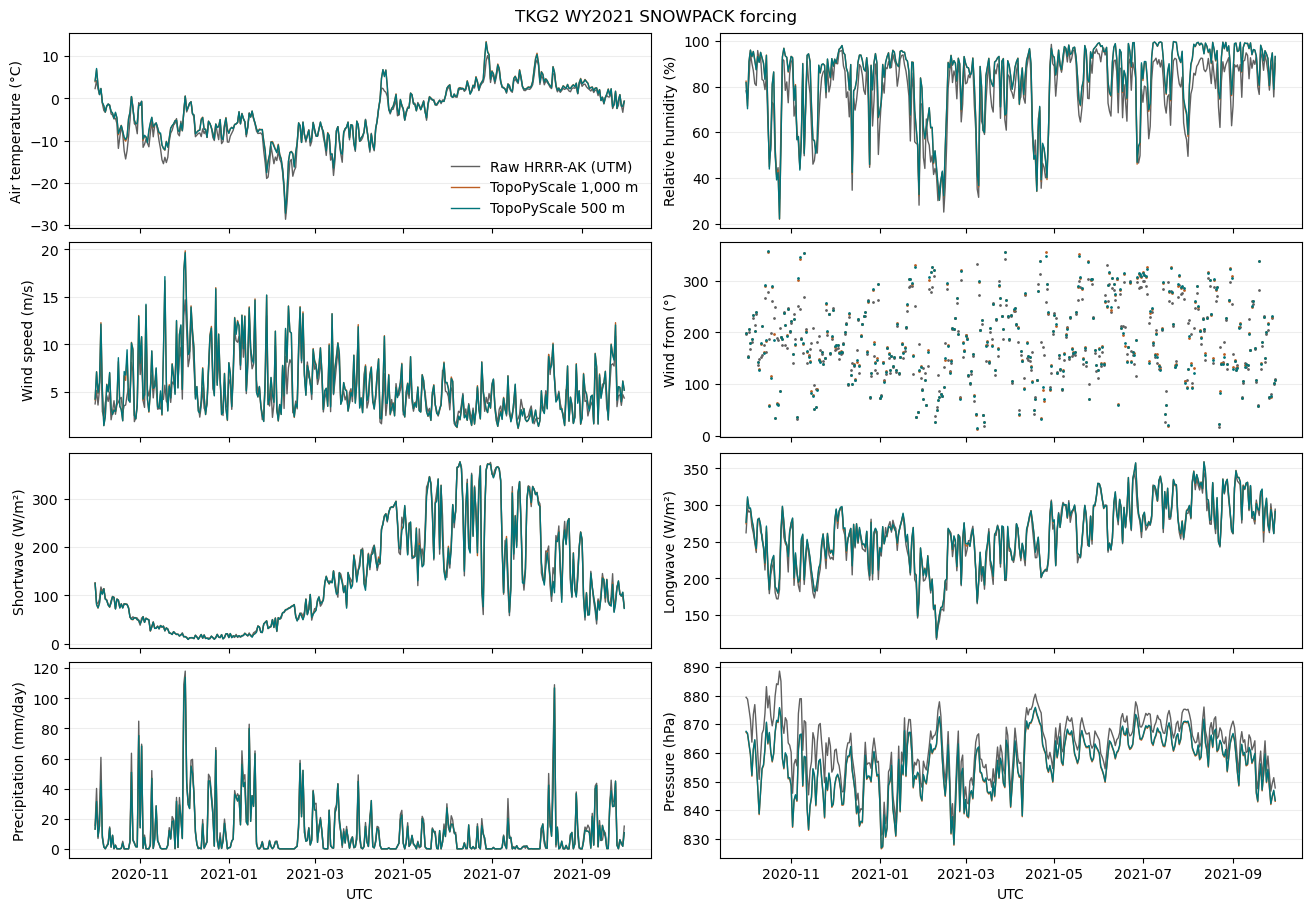

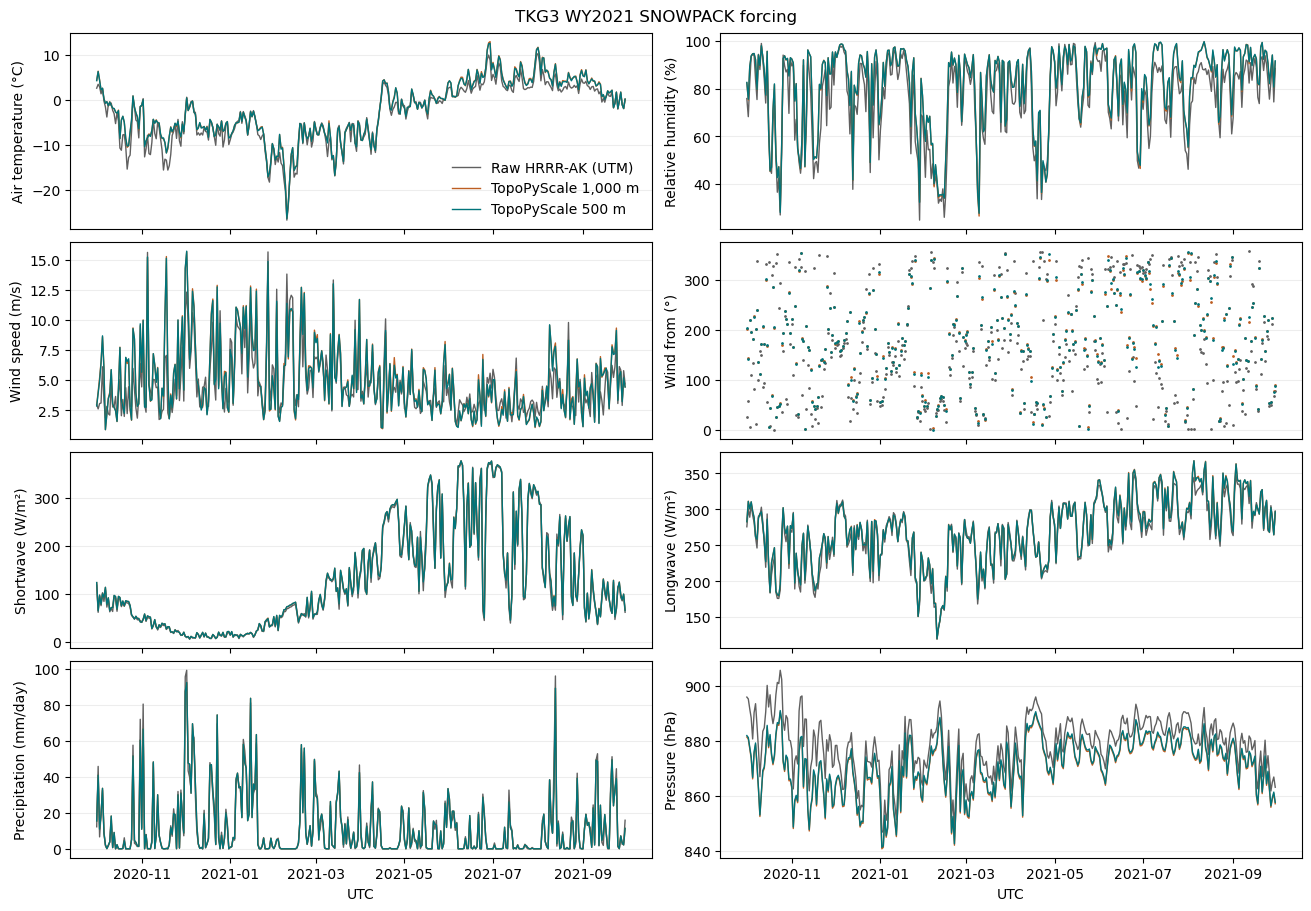

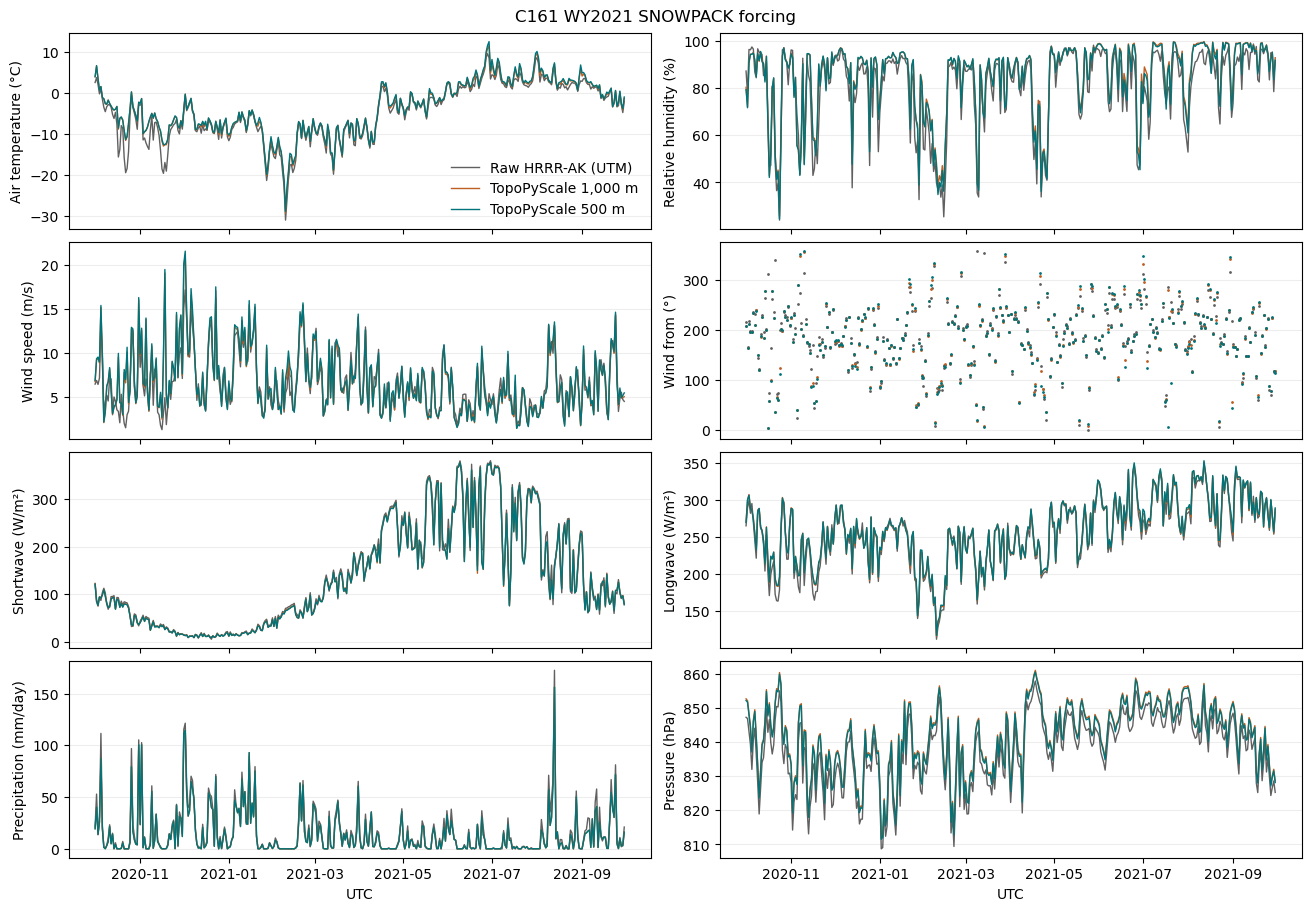

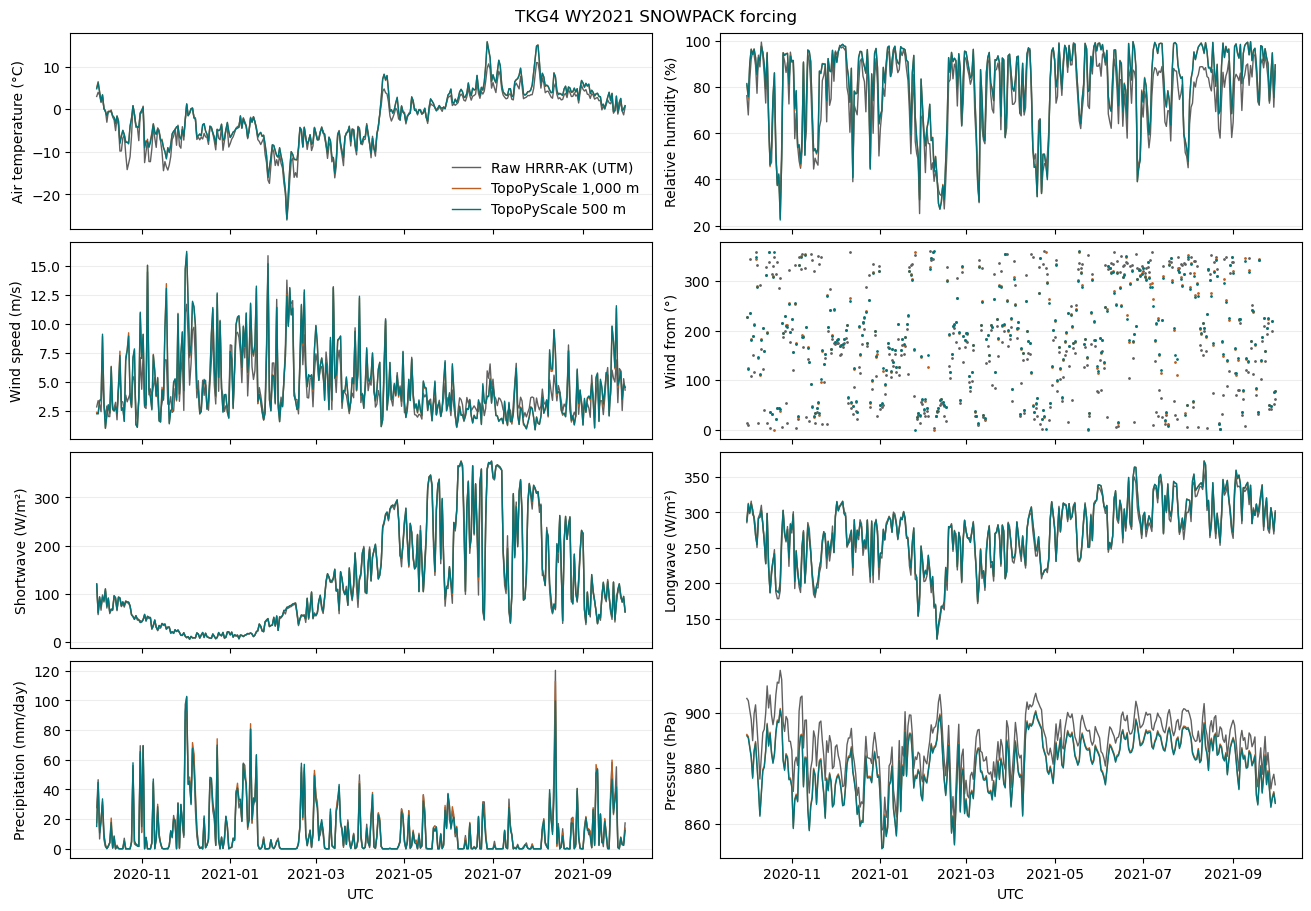

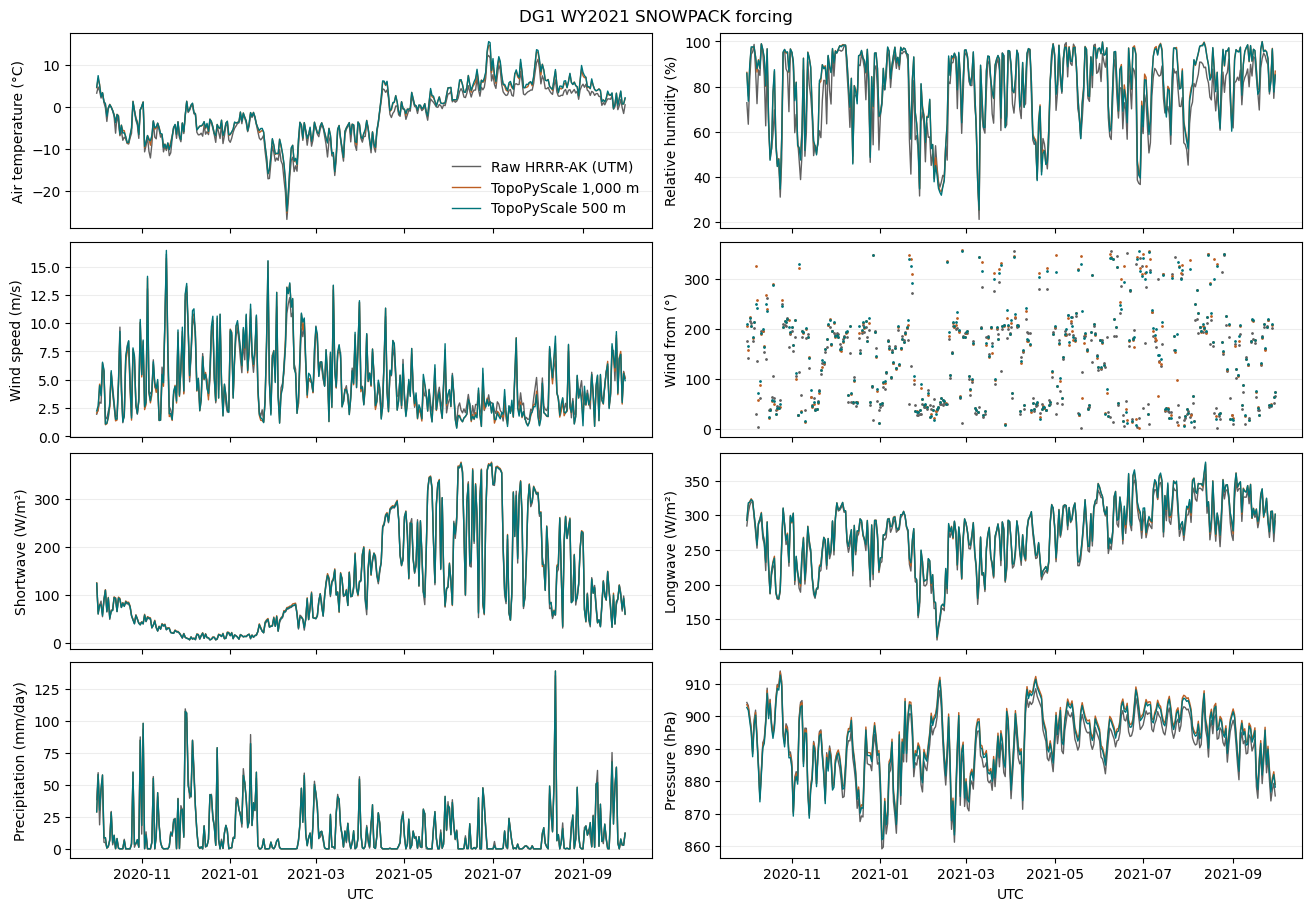

In [2]:
axis_labels = {"TA":"Air temperature (°C)", "RH":"Relative humidity (%)",
               "VW":"Wind speed (m/s)", "DW":"Wind from (°)",
               "ISWR":"Shortwave (W/m²)", "ILWR":"Longwave (W/m²)",
               "PSUM":"Precipitation (mm/day)" if frequency else "Precipitation (mm/h)",
               "PS":"Pressure (hPa)"}

def display_series(data, field):
    values = data[field]
    if field == "DW" and frequency:
        angle = np.deg2rad(values)
        u, v = -data.VW*np.sin(angle), -data.VW*np.cos(angle)
        values = np.rad2deg(np.arctan2(-u.resample(frequency).mean(),
                                      -v.resample(frequency).mean())) % 360
    elif frequency:
        grouped = values.resample(frequency)
        values = grouped.sum(min_count=1) if field == "PSUM" else grouped.mean()
    if field == "TA":
        return values - 273.15
    if field == "RH":
        return values * 100
    if field == "PS":
        return values / 100
    return values

for site, members in frames.items():
    fig, axes = plt.subplots(4,2,sharex=True,figsize=(13,9),layout="constrained")
    fig.suptitle(f"{site.upper()} WY2021 SNOWPACK forcing")
    for ax, (field,label) in zip(axes.ravel(), axis_labels.items()):
        for case, data in members.items():
            values = display_series(data,field)
            ax.plot(values.index,values,label=case,color=colors[case],
                    linewidth=0 if field=="DW" else 1,
                    marker="." if field=="DW" else None,markersize=2)
        ax.set_ylabel(label)
        ax.grid(axis="y", alpha=.22)
    axes[0,0].legend(frameon=False)
    for ax in axes[-1]:
        ax.set_xlabel("UTC")
    plt.show()


## Annual forcing and TopoPyScale cell elevations

In [3]:
display(pd.DataFrame(annual).set_index(["Site","Run"]).round(2))
display(pd.DataFrame(elevations).set_index(["Site","Run"]).round(2))

mean_temperature_C  total_precipitation_mm  \
Site Run                                                               
TKG2 Raw HRRR-AK (UTM)                 -3.84                 4234.43   
     TopoPyScale 1,000 m               -3.06                 3899.62   
     TopoPyScale 500 m                 -3.10                 3899.62   
TKG3 Raw HRRR-AK (UTM)                 -3.17                 4223.02   
     TopoPyScale 1,000 m               -2.08                 4193.77   
     TopoPyScale 500 m                 -2.12                 4193.77   
C161 Raw HRRR-AK (UTM)                 -4.83                 5708.27   
     TopoPyScale 1,000 m               -3.87                 5059.32   
     TopoPyScale 500 m                 -3.69                 5059.32   
TKG4 Raw HRRR-AK (UTM)                 -2.57                 4341.89   
     TopoPyScale 1,000 m               -1.49                 4397.21   
     TopoPyScale 500 m                 -1.47                 4265.95   
DG1  Raw HRRR-AK (UTM)                 -2.25                 4920.62   
     TopoPyScale 1,000 m               -1.09                 4950.83   
     TopoPyScale 500 m                 -0.99                 4950.83   

                          mean_shortwave_W_m2  mean_longwave_W_m2  
Site Run                                                           
TKG2 Raw HRRR-AK (UTM)                 134.01              259.07  
     TopoPyScale 1,000 m               133.43              262.85  
     TopoPyScale 500 m                 132.40              263.20  
TKG3 Raw HRRR-AK (UTM)                 126.13              266.46  
     TopoPyScale 1,000 m               128.57              270.59  
     TopoPyScale 500 m                 128.52              270.49  
C161 Raw HRRR-AK (UTM)                 138.49              255.63  
     TopoPyScale 1,000 m               135.99              258.91  
     TopoPyScale 500 m                 135.52              259.70  
TKG4 Raw HRRR-AK (UTM)                 123.47              270.25  
     TopoPyScale 1,000 m               125.43              273.95  
     TopoPyScale 500 m                 125.61              274.02  
DG1  Raw HRRR-AK (UTM)                 121.95              271.10  
     TopoPyScale 1,000 m               123.84              276.78  
     TopoPyScale 500 m                 122.95              277.28

site_elevation_m  grid_elevation_m  \
Site Run                                                       
TKG2 TopoPyScale 1,000 m            1326.0           1343.00   
     TopoPyScale 500 m              1326.0           1339.91   
TKG3 TopoPyScale 1,000 m            1203.0           1210.48   
     TopoPyScale 500 m              1203.0           1205.48   
C161 TopoPyScale 1,000 m            1483.0           1481.22   
     TopoPyScale 500 m              1483.0           1485.91   
TKG4 TopoPyScale 1,000 m            1120.0           1112.04   
     TopoPyScale 500 m              1120.0           1116.70   
DG1  TopoPyScale 1,000 m            1018.0           1007.56   
     TopoPyScale 500 m              1018.0           1015.58   

                          grid_minus_site_m  fallback_hours  
Site Run                                                     
TKG2 TopoPyScale 1,000 m              17.00               0  
     TopoPyScale 500 m                13.91               0  
TKG3 TopoPyScale 1,000 m               7.48               0  
     TopoPyScale 500 m                 2.48               0  
C161 TopoPyScale 1,000 m              -1.78               0  
     TopoPyScale 500 m                 2.91               0  
TKG4 TopoPyScale 1,000 m              -7.96               0  
     TopoPyScale 500 m                -3.30               0  
DG1  TopoPyScale 1,000 m             -10.44               0  
     TopoPyScale 500 m                -2.42               0

The TopoPyScale cell elevations are ArcticDEM grid averages. Fallback hours count occasions when the downscaler used a surface-only adjustment because it lacked a usable above-ground profile bracket. Site elevations are the elevations configured for SNOWPACK.